# Task 3: Fake News Detection

**Dataset:** Fake and Real News Dataset (`Fake.csv` + `True.csv`)

**Goal:** classify an article as Fake (0) or Real (1) from its title and text.

**Pipeline:** load data → explore and clean → stopword removal + lemmatization → stratified train/test split → TF-IDF → Logistic Regression and Linear SVM → accuracy/F1 evaluation → interpretation → word clouds.

> Run the notebook from top to bottom. The dataset must be available locally or in the Kaggle input directory. Report only the scores produced by your own run.

## 1. Imports & Setup

In [17]:
import re, string, warnings, os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

# Try downloading NLTK resources; if downloads are blocked, a documented fallback is used.
for resource in ("stopwords", "wordnet", "omw-1.4"):
    try:
        nltk.download(resource, quiet=True)
    except Exception:
        pass

## 2. Load Data

In [18]:
# Works with the common Kaggle path or a local folder containing Fake.csv and True.csv.
possible_dirs = [
    Path("/kaggle/input/datasets/clmentbisaillon/fake-and-real-news-dataset"),
    Path("/kaggle/input/fake-and-real-news-dataset"),
    Path("."),
    Path("./data"),
]
DATA_DIR = next((p for p in possible_dirs if (p / "Fake.csv").exists() and (p / "True.csv").exists()), None)
if DATA_DIR is None:
    raise FileNotFoundError(
        "Could not find Fake.csv and True.csv. Set DATA_DIR to the folder containing both files."
    )

fake = pd.read_csv(DATA_DIR / "Fake.csv")
true = pd.read_csv(DATA_DIR / "True.csv")
fake["label"] = 0  # 0 = Fake
true["label"] = 1  # 1 = Real
df = pd.concat([fake, true], ignore_index=True)

required = {"title", "text", "label"}
missing = required - set(df.columns)
if missing:
    raise ValueError(f"Dataset is missing required columns: {sorted(missing)}")

print("Data folder:", DATA_DIR.resolve())
print("Fake:", fake.shape, "| Real:", true.shape, "| Total:", df.shape)
df.head()

Data folder: /kaggle/input/datasets/clmentbisaillon/fake-and-real-news-dataset
Fake: (23481, 5) | Real: (21417, 5) | Total: (44898, 5)


,title,text,subject,date,label
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017",0
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017",0
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",News,"December 30, 2017",0
3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",News,"December 29, 2017",0
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,News,"December 25, 2017",0


## 3. Exploratory Data Analysis

In [19]:
print(df.info())
print("\nMissing values:\n", df.isna().sum())
print("\nDuplicated rows:", df.duplicated().sum())
print("\nClass distribution:\n", df["label"].value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 44898 entries, 0 to 44897
Data columns (total 5 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   title    44898 non-null  object
 1   text     44898 non-null  object
 2   subject  44898 non-null  object
 3   date     44898 non-null  object
 4   label    44898 non-null  int64 
dtypes: int64(1), object(4)
memory usage: 1.7+ MB
None

Missing values:
 title      0
text       0
subject    0
date       0
label      0
dtype: int64

Duplicated rows: 209

Class distribution:
 label
0    23481
1    21417
Name: count, dtype: int64


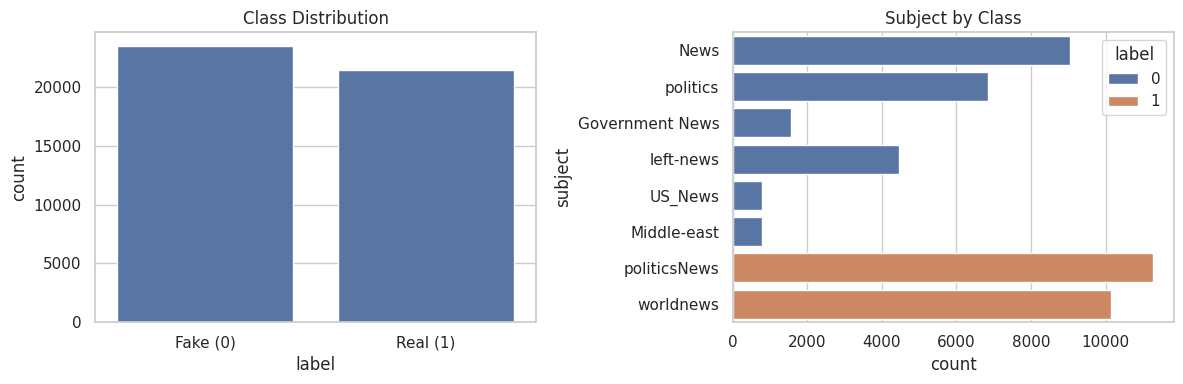

In [20]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(x="label", data=df, ax=ax[0])
ax[0].set_xticks([0, 1], labels=["Fake (0)", "Real (1)"])
ax[0].set_title("Class Distribution")
if "subject" in df.columns:
    sns.countplot(y="subject", hue="label", data=df, ax=ax[1])
    ax[1].set_title("Subject by Class")
else:
    ax[1].text(0.5, 0.5, "No subject column", ha="center", va="center")
    ax[1].set_axis_off()
plt.tight_layout()
plt.show()

### Data leakage and dataset limitations

This dataset can contain shortcuts that make classification look easier than it would be on new sources: Reuters-style wording, duplicated articles, and a `subject` column that may be strongly associated with labels. We remove duplicate/empty articles and Reuters mentions from the text, and use only title + article text as model features (not `subject` or `date`). This reduces obvious leakage but does **not** guarantee a fully unbiased evaluation; the dataset may still contain source, topic, or time-specific patterns.

In [21]:
print("Real articles containing 'Reuters':",
      round(true["text"].str.contains("Reuters", case=False, na=False).mean()*100, 1), "%")
print("Fake articles containing 'Reuters':",
      round(fake["text"].str.contains("Reuters", case=False, na=False).mean()*100, 1), "%")
print("\nSubjects in Fake:", fake["subject"].unique())
print("Subjects in True:", true["subject"].unique())

Real articles containing 'Reuters': 99.8 %
Fake articles containing 'Reuters': 1.4 %

Subjects in Fake: ['News' 'politics' 'Government News' 'left-news' 'US_News' 'Middle-east']
Subjects in True: ['politicsNews' 'worldnews']


## 4. Cleaning & Preprocessing

In [22]:
# Normalize missing values, remove duplicates, and discard rows with no title and no article text.
before = len(df)
df["title"] = df["title"].fillna("").astype(str)
df["text"] = df["text"].fillna("").astype(str)
df = df.drop_duplicates(subset=["title", "text"]).reset_index(drop=True)
df = df[(df["title"].str.strip() != "") | (df["text"].str.strip() != "")].reset_index(drop=True)
print(f"Removed {before - len(df)} duplicate/empty rows -> {len(df)} remain")

# Combine title and content so both contribute to the prediction.
df["content"] = df["title"] + " " + df["text"]

Removed 5793 duplicate/empty rows -> 39105 remain


In [23]:
try:
    STOP_WORDS = set(stopwords.words("english"))
except LookupError:
    from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
    STOP_WORDS = set(ENGLISH_STOP_WORDS)
    print("NLTK stopwords unavailable; using scikit-learn's English stopword list.")

try:
    lemmatizer = WordNetLemmatizer()
    lemmatizer.lemmatize("tests")  # verifies WordNet data is available
    USE_LEMMA = True
except LookupError:
    USE_LEMMA = False
    print("WARNING: WordNet is unavailable, so lemmatization will be skipped. Enable downloads or install NLTK WordNet data for the full assignment pipeline.")

# Remove URLs and Reuters source markers that can act as dataset shortcuts.
REUTERS_PREFIX = re.compile(r"^.{0,100}?\(reuters\)\s*-?\s*", flags=re.IGNORECASE)
URL = re.compile(r"https?://\S+|www\.\S+", flags=re.IGNORECASE)
PUNCT_TABLE = str.maketrans("", "", string.punctuation)
lemma_cache = {}

def lemma(word):
    if not USE_LEMMA:
        return word
    if word not in lemma_cache:
        lemma_cache[word] = lemmatizer.lemmatize(word)
    return lemma_cache[word]

def clean_text(text):
    text = str(text)
    text = REUTERS_PREFIX.sub("", text)
    text = URL.sub(" ", text.lower())
    text = re.sub(r"\breuters\b", " ", text)
    text = text.translate(PUNCT_TABLE)
    text = re.sub(r"[^a-z\s]", " ", text)
    tokens = [lemma(w) for w in text.split() if w not in STOP_WORDS and len(w) > 2]
    return " ".join(tokens)

df["clean"] = df["content"].apply(clean_text)
df = df[df["clean"].str.strip() != ""].reset_index(drop=True)
print("Lemmatization enabled:", USE_LEMMA)
df[["content", "clean"]].head(3)

Lemmatization enabled: True


,content,clean
0,Donald Trump Sends Out Embarrassing New Year’...,donald trump sends embarrassing new year eve m...
1,Drunk Bragging Trump Staffer Started Russian ...,drunk bragging trump staffer started russian c...
2,Sheriff David Clarke Becomes An Internet Joke...,sheriff david clarke becomes internet joke thr...


## 5. Train / Test Split

In [24]:
X_train, X_test, y_train, y_test = train_test_split(
    df["clean"], df["label"], test_size=0.2, stratify=df["label"], random_state=RANDOM_STATE
)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Training label proportions:\n", y_train.value_counts(normalize=True).sort_index().round(3))

Train: (31280,) | Test: (7820,)
Training label proportions:
 label
0    0.458
1    0.542
Name: proportion, dtype: float64


## 6. TF-IDF Vectorization
Fitted on the **training set only** to avoid leakage.

In [25]:
# Fit TF-IDF on training text only; transform the test set without refitting.
tfidf = TfidfVectorizer(
    max_features=50000, ngram_range=(1, 2), min_df=3, max_df=0.9, sublinear_tf=True
)
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)
print("TF-IDF train matrix:", X_train_tfidf.shape)
print("TF-IDF test matrix:", X_test_tfidf.shape)

TF-IDF train matrix: (31280, 50000)
TF-IDF test matrix: (7820, 50000)


## 7. Model Training & Evaluation

In [26]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, C=1.0, random_state=RANDOM_STATE),
    "Linear SVM": LinearSVC(C=1.0, random_state=RANDOM_STATE),
}

results, preds = [], {}
for name, model in models.items():
    model.fit(X_train_tfidf, y_train)
    y_pred = model.predict(X_test_tfidf)
    preds[name] = y_pred
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "F1 (Fake)": f1_score(y_test, y_pred, pos_label=0),
        "F1 (Real)": f1_score(y_test, y_pred, pos_label=1),
        "F1 (macro)": f1_score(y_test, y_pred, average="macro"),
    })
    print(f"===== {name} =====")
    print(classification_report(y_test, y_pred, labels=[0, 1], target_names=["Fake", "Real"], digits=4, zero_division=0))

results_df = pd.DataFrame(results).set_index("Model").sort_values("F1 (macro)", ascending=False).round(4)
display(results_df)
best_model_name = results_df.index[0]
print("Best model by macro F1:", best_model_name)

===== Logistic Regression =====
              precision    recall  f1-score   support

        Fake     0.9907    0.9768    0.9837      3581
        Real     0.9806    0.9922    0.9864      4239

    accuracy                         0.9852      7820
   macro avg     0.9857    0.9845    0.9850      7820
weighted avg     0.9852    0.9852    0.9852      7820

===== Linear SVM =====
              precision    recall  f1-score   support

        Fake     0.9938    0.9852    0.9895      3581
        Real     0.9876    0.9948    0.9912      4239

    accuracy                         0.9904      7820
   macro avg     0.9907    0.9900    0.9903      7820
weighted avg     0.9904    0.9904    0.9904      7820



,Accuracy,F1 (Fake),F1 (Real),F1 (macro)
Model,,,,
Linear SVM,0.9904,0.9895,0.9912,0.9903
Logistic Regression,0.9852,0.9837,0.9864,0.9850


Best model by macro F1: Linear SVM


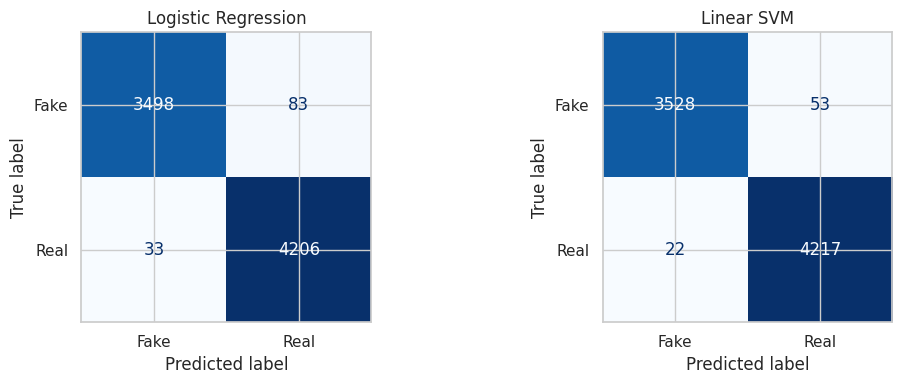

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (name, y_pred) in zip(axes, preds.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=["Fake", "Real"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)
plt.tight_layout(); plt.show()

## 8. Model Interpretation — Most Influential Terms

Top terms associated with FAKE:
 video, via, image, image via, gop, obama, president trump, even, hillary, america, american, like, watch, breaking, president obama, wire, rep, sen, read, get

Top terms associated with REAL:
 said, president donald, wednesday, tuesday, thursday, friday, monday, said statement, nov, minister, representative, spokesman, president barack, told, told reporter, comment, trump said, democratic, presidential, statement


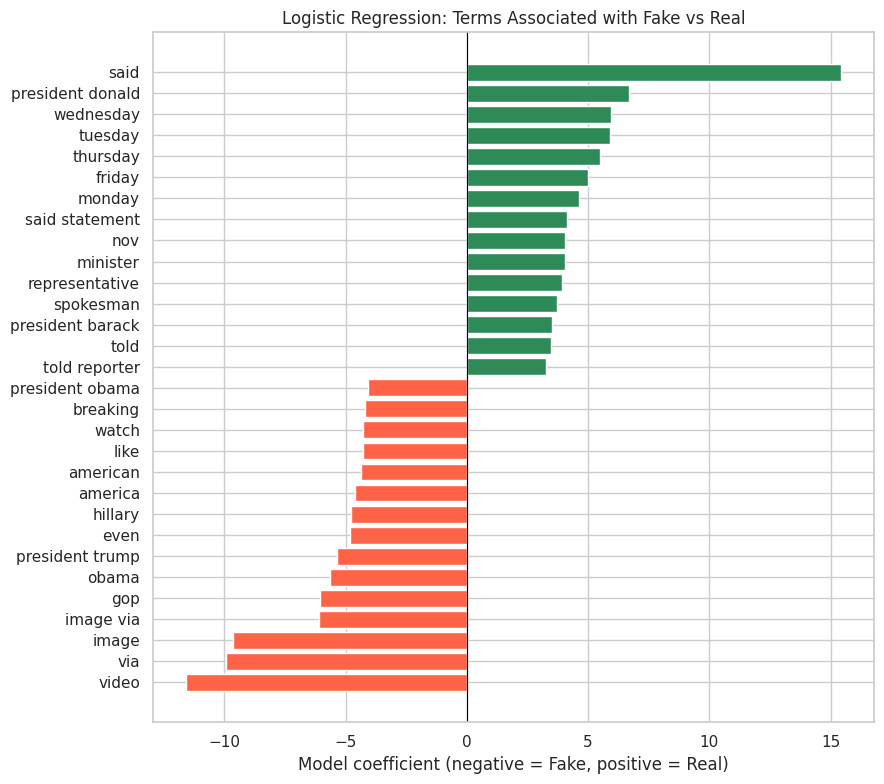

In [28]:
# Logistic Regression coefficients: negative values indicate Fake (class 0), positive indicate Real (class 1).
lr = models["Logistic Regression"]
feature_names = np.array(tfidf.get_feature_names_out())
coefs = lr.coef_[0]

top_fake_idx = np.argsort(coefs)[:20]
top_real_idx = np.argsort(coefs)[-20:][::-1]
print("Top terms associated with FAKE:\n", ", ".join(feature_names[top_fake_idx]))
print("\nTop terms associated with REAL:\n", ", ".join(feature_names[top_real_idx]))

plot_idx = np.concatenate([top_fake_idx[:15], top_real_idx[:15]])
plot_terms = feature_names[plot_idx]
plot_values = coefs[plot_idx]
plot_colors = ["tomato" if value < 0 else "seagreen" for value in plot_values]
order = np.argsort(plot_values)
plt.figure(figsize=(9, 8))
plt.barh(plot_terms[order], plot_values[order], color=np.array(plot_colors)[order])
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Logistic Regression: Terms Associated with Fake vs Real")
plt.xlabel("Model coefficient (negative = Fake, positive = Real)")
plt.tight_layout()
plt.show()

## 9. Predict on New Text

In [29]:
def predict_news(title, text, model_name="Logistic Regression"):
    """Predict whether a news article is Fake or Real using its title and body."""
    cleaned = clean_text(str(title) + " " + str(text))
    vectorized = tfidf.transform([cleaned])
    prediction = models[model_name].predict(vectorized)[0]
    return "REAL" if prediction == 1 else "FAKE"

print(predict_news(
    "Senate passes budget bill after lengthy debate",
    "The Senate voted on Thursday to approve the federal budget, officials said."
))
print(predict_news(
    "SHOCKING: You won't believe what they are hiding from you!!!",
    "Wake up people, the media will never tell you this truth about the elite."
))

REAL
FAKE


## 10. Bonus: Word Clouds — Fake vs Real

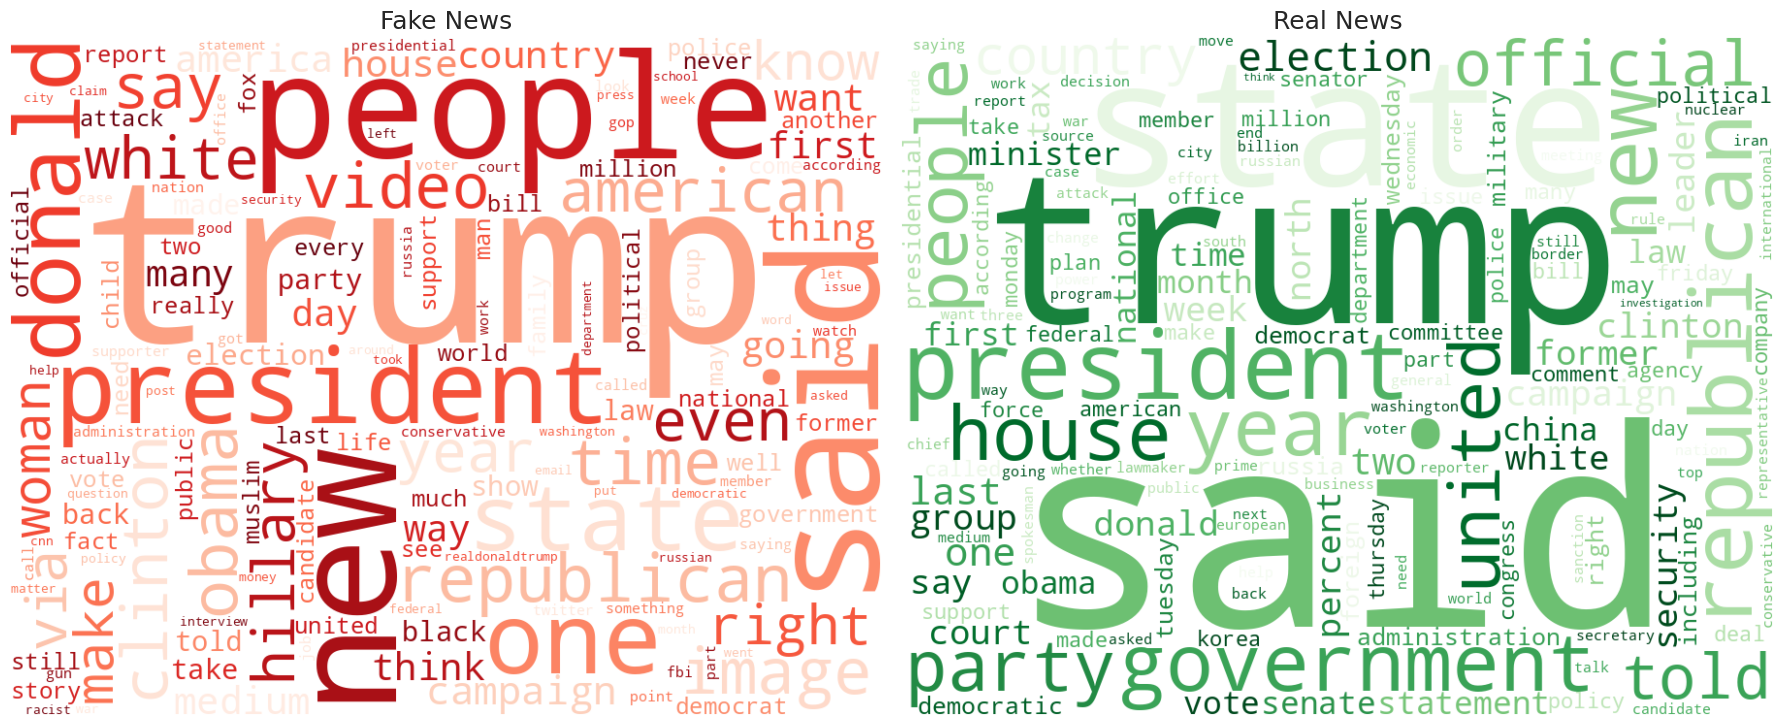

In [30]:
# Optional bonus: if wordcloud is missing, install it with `pip install wordcloud` and rerun this cell.
from wordcloud import WordCloud

fake_text = " ".join(df.loc[df["label"] == 0, "clean"])
real_text = " ".join(df.loc[df["label"] == 1, "clean"])

fig, axes = plt.subplots(1, 2, figsize=(18, 8))
for ax, text, title, cmap in [
    (axes[0], fake_text, "Fake News", "Reds"),
    (axes[1], real_text, "Real News", "Greens"),
]:
    if text.strip():
        cloud = WordCloud(width=900, height=700, background_color="white",
                          colormap=cmap, max_words=150, collocations=False).generate(text)
        ax.imshow(cloud, interpolation="bilinear")
        ax.set_title(title, fontsize=18)
    else:
        ax.text(0.5, 0.5, "No text available", ha="center", va="center")
    ax.axis("off")
plt.tight_layout()
plt.show()

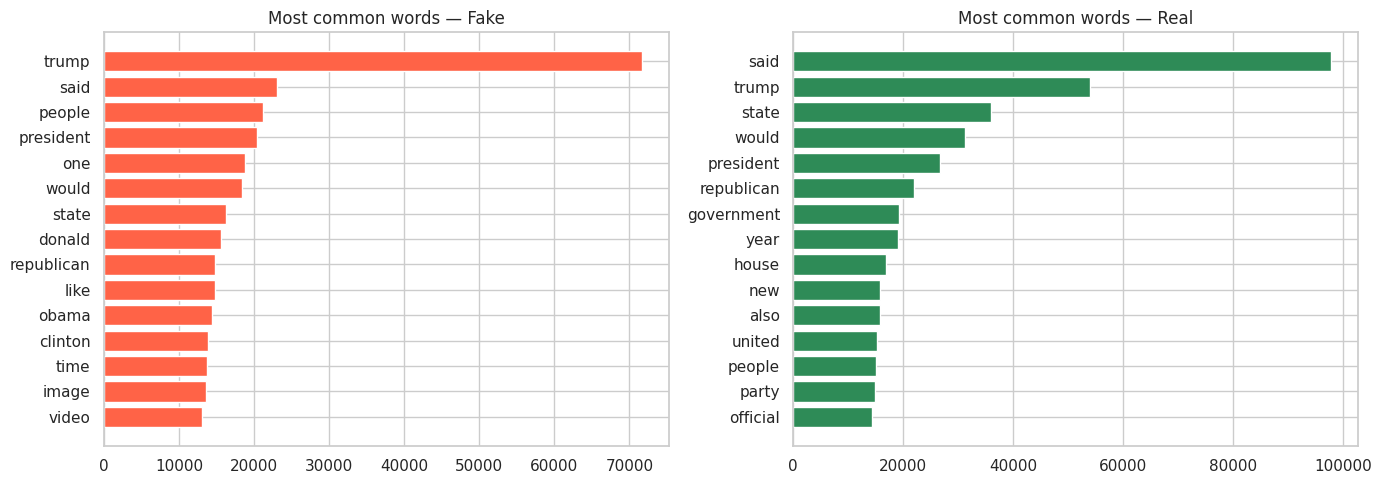

In [31]:
from collections import Counter

def top_words(series, n=15):
    counts = Counter(" ".join(series).split())
    return counts.most_common(n)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, label, title, color in [(axes[0], 0, "Fake", "tomato"), (axes[1], 1, "Real", "seagreen")]:
    words_counts = top_words(df.loc[df["label"] == label, "clean"], n=15)
    if words_counts:
        words, counts = zip(*words_counts)
        ax.barh(list(words)[::-1], list(counts)[::-1], color=color)
    ax.set_title(f"Most common words — {title}")
plt.tight_layout()
plt.show()

## 11. Conclusion and Limitations

After running all cells, use the evaluation table above to report the measured Accuracy and F1-scores for Logistic Regression and Linear SVM. Do not assume a score before running the notebook.

- The model uses title + article text, English stopword removal, optional NLTK lemmatization, and TF-IDF features (unigrams and bigrams).
- Logistic Regression and Linear SVM are compared using Accuracy and F1-score; the confusion matrices show the types of mistakes made.
- Word clouds visualize frequent terms in each class; frequent words are not proof that an individual article is true or false.
- **Limitations:** the dataset is largely US political news from a particular period. Results may not generalize to other topics, countries, publishers, or current events. Dataset artifacts can remain even after removing obvious Reuters/source clues.
- **Future work:** cross-validation, hyperparameter tuning, evaluation on a separate dataset from different sources, and comparison with transformer-based models.

**Important:** this is a text classifier, not a fact-checking system. Verify consequential claims using reliable independent sources.